# Analytics Report & Insights Documentation
## Technology-Stock Performance Review, 1990 – 2022

**Programme:** Yuva Intern  |  **Student:** Lokesh Patwal  |  **Internship period:** 01 October 2026 – 26 November 2026

This notebook is a complete, reproducible analytics workflow:

`Business problem → Business questions → Dataset → Data-quality checks → KPIs → Analysis → Visualisations → Findings → Business insights → Recommendations`

Every number in the text was calculated from the dataset by the code cells in this notebook. The last cell re-calculates each number quoted in the text and stops with an error if one does not match.

**How the six official objectives are covered**

| Objective | Where in this notebook |
|---|---|
| 1 Define business objectives | Section 2 |
| 2 Analyse data and identify findings | Sections 6 – 9 |
| 3 Create meaningful visualisations | Section 9 (12 figures, saved in `reports/figures/`) |
| 4 Generate business insights | Section 10 |
| 5 Prepare an executive summary | Section 11 (and `reports/executive_summary.md`) |
| 6 Provide actionable recommendations | Section 12 |

> **Educational notice.** This is a data-analysis exercise on historical prices. It is not investment advice, and past performance does not predict future results.

## 2. Business understanding

### A. Business background
A small technology-focused investment club (an *assumed* organisation used for this exercise) holds shares in seven long-established technology companies: **IBM, Apple, Microsoft, Xerox, Amazon, Alphabet (Google) and Adobe**. Once a year its investment committee reviews how each holding has performed and how risky it has been, compared with the broad market (the **S&P 500** index) and the technology-heavy **NASDAQ Composite** index. Dell is also in the dataset but has only a short price history.

### B. Problem statement
The committee has price histories but no consolidated analysis. It needs to know **which holdings created value, how much risk was taken to get it, how the holdings behave when markets fall, and whether holding all seven together reduces risk**, so it can decide where to keep, review or limit its positions.

### C. Business objectives
1. Measure the growth and risk of each holding on a fair, comparable basis.
2. Understand how closely each holding follows the market and how it behaved in past market downturns.
3. Check whether combining the holdings lowers risk.
4. Identify unusual months that deserve investigation.
5. Turn the evidence into prioritised, testable recommendations.

### D. Stakeholders (assumed, for this exercise)
| Stakeholder | What they need from the report |
|---|---|
| Investment committee chair | A one-page summary and clear recommendations |
| Portfolio manager | Return, risk and ranking of each holding |
| Risk manager | Drawdowns, stress behaviour, extreme months |

### E. Key business questions
| ID | Business question |
|---|---|
| Q1 | Which holdings created the most value, and how does that compare with the market indices? |
| Q2 | How risky was each holding (volatility, largest falls, spread of monthly returns)? |
| Q3 | Which holdings delivered the most growth for the risk taken? |
| Q4 | How strongly does each holding follow the market (beta, correlation)? |
| Q5 | How did the holdings behave in past market-stress periods? |
| Q6 | Does holding all seven together reduce risk? |
| Q7 | How consistent were returns from year to year? |
| Q8 | Which months were unusual, and when did they happen? |

### F. Reporting requirements: question → metric → visual → decision
| Question | Metrics needed | Visual / table | Decision it supports |
|---|---|---|---|
| Q1 | Total return, CAGR | Fig 1, Fig 2, KPI tables | Which holdings stay as core positions |
| Q2 | Annualised volatility, maximum drawdown, monthly-return spread | Fig 4, Fig 5, Fig 6 | How large each position should be |
| Q3 | Return-to-risk ratio | Fig 3 | How to rank holdings for allocation |
| Q4 | Beta, correlation with S&P 500 | Fig 7, Fig 8 | How much market exposure the club carries |
| Q5 | Largest fall inside defined stress windows | Fig 9 | Whether risk limits and stress tests are needed |
| Q6 | Average pairwise correlation, equal-weight basket volatility and drawdown | Fig 10, Fig 12 | Whether to keep a diversified basket |
| Q7 | Calendar-year returns, share of positive years | Fig 11 | What return consistency to expect |
| Q8 | Months more than 3 standard deviations from a stock's own average | Outlier table | Which events to investigate |

## 3. Dataset source and description

| Item | Detail |
|---|---|
| **Name** | `Stocks.csv` – monthly stock prices |
| **Original source** | Yahoo Finance, <https://finance.yahoo.com> (stated in the first line of the file) |
| **How it is accessed** | The file is part of Matplotlib's `sample_data` folder (`matplotlib.cbook.get_sample_data("Stocks.csv")`). It is read from the installed Matplotlib package: no download, account or API key is needed. |
| **Publisher / usage conditions** | Prices come from Yahoo Finance; Matplotlib distributes the file with its documentation examples. Yahoo's own terms govern reuse of its data, so this repository **does not copy the raw file**; it reads it from Matplotlib at run time. |
| **Size and period** | 524 rows × 11 columns, 1990-01-01 to 2022-06-28 (details in Section 6) |
| **Columns** | `Date` plus ten price columns (data dictionary below) |
| **Business context** | Long-run price history of well-known technology companies and two US stock-market indices |
| **Why it was chosen** | It is real data from a recognised source, is available without internet access or credentials, has a long period (over 32 years), and supports return, risk, market-relationship, stress-period and diversification analysis |
| **Limitations and biases** | Prices only (no revenue, profit, volume, dividends or company information); the companies are today's well-known names (survivorship bias); monthly frequency; the file does not state whether prices are adjusted. See Section 13. |

> **Why not a sales dataset?** The working environment for this project could not reach most public data sites (for example data portals and the UCI repository), and no retail or sales dataset with clear reuse terms was available offline. Rather than invent data, the project uses this real dataset. If a sales dataset is preferred, the same workflow (business questions → KPIs → charts → insights → recommendations) applies.

**Data dictionary**

| Column | Meaning | Type | Unit |
|---|---|---|---|
| `Date` | Date of the monthly observation (normally the first day of the month) | text → date | – |
| `IBM`, `AAPL`, `MSFT`, `XRX`, `AMZN`, `DELL`, `GOOGL`, `ADBE` | Monthly price of IBM, Apple, Microsoft, Xerox, Amazon, Dell, Alphabet (Google Class A), Adobe | decimal | Assumed US dollars per share (not stated in the file) |
| `^GSPC` | S&P 500 index level | decimal | Index points |
| `^IXIC` | NASDAQ Composite index level | decimal | Index points |

## 4. Environment and imports

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Make the project's own modules importable whether the notebook is started from
# the project folder or from the notebooks/ folder.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

from src import data_loader as dl
from src import data_cleaning as dc
from src import kpi_analysis as kpi
from src import visualization as viz

viz.apply_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
FIG_DIR = dl.FIGURES_DIR

print("Project folder:", PROJECT_ROOT)
print("pandas", pd.__version__, "| numpy", np.__version__)

Project folder: /home/claude/analytics-report-insights
pandas 3.0.5 | numpy 2.5.3


## 5. Data loading
The raw file is loaded exactly as stored. Nothing is changed in this step.

In [2]:
raw = dl.load_raw_prices()
print("Source file:", dl.locate_sample_file().name, "(read from the installed Matplotlib package)")
print("Rows x columns:", raw.shape)
raw.head()

Source file: Stocks.csv (read from the installed Matplotlib package)
Rows x columns: (524, 11)


,Date,IBM,AAPL,MSFT,XRX,AMZN,DELL,GOOGL,ADBE,^GSPC,^IXIC
0,1990-01-01,10.970438,0.242512,0.403759,11.202082,NaN,NaN,NaN,1.379061,329.079987,415.799988
1,1990-02-01,11.554416,0.242512,0.431040,10.394725,NaN,NaN,NaN,1.779084,331.890015,425.799988
2,1990-02-05,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1990-03-01,11.951694,0.288017,0.483420,11.394058,NaN,NaN,NaN,2.234883,339.940002,435.500000
4,1990-04-01,12.275476,0.281756,0.506336,10.139430,NaN,NaN,NaN,2.253145,330.799988,420.100006


In [3]:
print(raw.dtypes.to_string())
raw.tail()

Date         str
IBM      float64
AAPL     float64
MSFT     float64
XRX      float64
AMZN     float64
DELL     float64
GOOGL    float64
ADBE     float64
^GSPC    float64
^IXIC    float64


,Date,IBM,AAPL,MSFT,XRX,AMZN,DELL,GOOGL,ADBE,^GSPC,^IXIC
519,2022-04-01,130.625443,157.418701,276.875122,17.40,124.281502,46.682991,2282.189941,395.950012,4131.930176,12334.639648
520,2022-05-01,137.175980,148.621628,271.238251,18.82,120.209503,49.939999,2275.239990,416.480011,4132.149902,12081.389648
521,2022-05-09,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
522,2022-06-01,141.860001,137.440002,256.480011,15.82,107.400002,48.939999,2240.149902,365.630005,3821.550049,11181.540039
523,2022-06-28,141.860001,137.440002,256.480011,15.82,107.400002,48.939999,2240.149902,365.630005,3821.550049,11181.540039


## 6. Data-quality assessment
Each check below asks a question, shows the real result, and states what it means for the analysis.

In [4]:
q = dc.quality_report(raw)
summary = pd.Series({
    "Rows": q["rows"],
    "Columns": q["columns"],
    "First date": q["first_date"].date(),
    "Last date": q["last_date"].date(),
    "Dates in increasing order": q["dates_increasing"],
    "Rows with no price at all": q["empty_rows"],
    "Exact duplicate rows": q["exact_duplicate_rows"],
    "Duplicate dates": q["duplicate_dates"],
    "Extra rows in an already-seen month (rows with prices)": q["same_month_duplicates"],
    "Prices that are zero or negative": q["non_positive_prices"],
    "Missing price cells (all columns)": q["missing_cells"],
}, name="Result")
summary.to_frame()

,Result
Rows,524
Columns,11
First date,1990-01-01
Last date,2022-06-28
Dates in increasing order,True
Rows with no price at all,133
Exact duplicate rows,0
Duplicate dates,0
Extra rows in an already-seen month (rows with prices),1
Prices that are zero or negative,0


In [5]:
# Missing values by column, before any cleaning
prices_raw = raw.drop(columns="Date")
missing = pd.DataFrame({"missing": prices_raw.isna().sum(),
                        "missing_pct": (prices_raw.isna().mean() * 100).round(1)})
missing

,missing,missing_pct
IBM,133,25.4
AAPL,133,25.4
MSFT,133,25.4
XRX,133,25.4
AMZN,222,42.4
DELL,453,86.5
GOOGL,309,59.0
ADBE,133,25.4
^GSPC,133,25.4
^IXIC,133,25.4


**Check 1 – rows without any price.** The table above shows 133 missing values in *every* column, which suggests the same rows are empty across all columns. The next cell checks that.

In [6]:
empty = raw[dc.empty_row_mask(raw)]
print("Rows where every price is missing:", len(empty))
print("These rows are dated in months:", sorted(int(m) for m in pd.to_datetime(empty["Date"]).dt.month.unique()))
print("Share of those rows that fall on the 1st of a month:", (pd.to_datetime(empty["Date"]).dt.day == 1).mean())
print("Example dates:", empty["Date"].head(6).tolist())

Rows where every price is missing: 133
These rows are dated in months: [2, 5, 8, 11]
Share of those rows that fall on the 1st of a month: 0.0
Example dates: ['1990-02-05', '1990-05-04', '1990-08-06', '1990-11-05', '1991-02-04', '1991-05-06']


**Interpretation.** 133 rows (25.4 % of the file) contain a date but no price in any column. They all fall in February, May, August or November, roughly once per quarter, on days other than the 1st. They are placeholder rows, not months with missing data, and carry no information. They are removed in the cleaning step. This is a fact established by the code above; why Yahoo's export contains them is not documented in the file.

In [7]:
# Missing values that remain once the empty rows are ignored
priced = raw[~dc.empty_row_mask(raw)]
first_valid = {t: priced.loc[priced[t].notna(), "Date"].iloc[0] for t in dc.ticker_columns(raw)}
remaining_missing = priced.drop(columns="Date").isna().sum()
pd.DataFrame({"first month with a price": first_valid, "missing months": remaining_missing})

,first month with a price,missing months
IBM,1990-01-01,0
AAPL,1990-01-01,0
MSFT,1990-01-01,0
XRX,1990-01-01,0
AMZN,1997-06-01,89
DELL,2016-09-01,320
GOOGL,2004-09-01,176
ADBE,1990-01-01,0
^GSPC,1990-01-01,0
^IXIC,1990-01-01,0


**Interpretation.** After the empty rows are ignored, Amazon, Alphabet and Dell still have missing values, but only *before* their first price (Amazon from June 1997, Alphabet from September 2004, Dell from September 2016). These gaps are real: the company had no price in the file yet. They are **not filled in**, because inventing prices would distort returns. Dell has only 70 months of prices once the duplicate June 2022 row is removed, so it is not compared with the longer histories.

In [8]:
# Duplicates: exact rows, repeated dates, and a repeated month
print("Exact duplicate rows:", int(raw.duplicated().sum()))
print("Repeated dates:", int(pd.to_datetime(raw["Date"]).duplicated().sum()))
same_month = priced[dc.same_month_duplicate_mask(priced)]
print("Rows that repeat an already-seen month:", len(same_month))
june = raw[raw["Date"].str.startswith("2022-06")].set_index("Date").T
june["identical"] = june.iloc[:, 0] == june.iloc[:, 1]
june

Exact duplicate rows: 0
Repeated dates: 0
Rows that repeat an already-seen month: 1


Date,2022-06-01,2022-06-28,identical
IBM,141.860001,141.860001,True
AAPL,137.440002,137.440002,True
MSFT,256.480011,256.480011,True
XRX,15.820000,15.820000,True
AMZN,107.400002,107.400002,True
DELL,48.939999,48.939999,True
GOOGL,2240.149902,2240.149902,True
ADBE,365.630005,365.630005,True
^GSPC,3821.550049,3821.550049,True
^IXIC,11181.540039,11181.540039,True


**Interpretation.** There are no exact duplicate rows and no repeated dates. However, June 2022 appears twice (dated 2022-06-01 and 2022-06-28) and all ten prices are identical. The second row is a duplicate of the same month, and it also shows that the June 2022 value is a price **as of 28 June 2022**, so June 2022 is a partial month. The duplicate row is removed, and the partial month is kept and noted as a limitation.

In [9]:
# Price validity and ranges
checks = pd.DataFrame({"minimum": prices_raw.min(), "maximum": prices_raw.max()})
checks["all prices > 0"] = prices_raw.min() > 0
checks

,minimum,maximum,all prices > 0
IBM,5.574151,141.997864,True
AAPL,0.100198,177.083878,True
MSFT,0.403759,334.846161,True
XRX,6.248927,102.471207,True
AMZN,0.077083,175.353500,True
DELL,13.321450,56.414822,True
GOOGL,64.864868,2960.919922,True
ADBE,1.121038,669.849976,True
^GSPC,304.000000,4766.180176,True
^IXIC,329.799988,15644.969727,True


**Interpretation.** Every price is above zero, so percentage returns can be calculated. The wide ranges (for example Alphabet's maximum above 2,900 and Apple's minimum of 0.10) are consistent with long histories, and with prices that have been adjusted for share splits. The file does not say which adjustments were made; this is documented as an assumption in Section 13.

**Check – are the fields suitable for the planned KPIs?**

| KPI group | Fields needed | Available? |
|---|---|---|
| Total return, CAGR, volatility, drawdown, beta, correlation | Monthly price per ticker | Yes |
| Calendar-year returns | December price of each year | Yes |
| Revenue, profit, margin, trading volume, dividend yield | Company financials, volume, dividends | **No – not in the file, so none of these are calculated** |

## 7. Data cleaning and preprocessing
Cleaning steps, each justified by a finding in Section 6:
1. Convert `Date` to a real date.
2. Remove the 133 rows with no price.
3. Keep only the first row of each calendar month (removes the duplicate June 2022 row).
4. Use the month as the table index. Remaining missing values (before a company's first price) are left as missing.

The raw data are never modified; the cleaned table is a new object.

In [10]:
prices = dc.clean_prices(raw)
after_missing = int(prices.isna().sum().sum())

before_after = pd.DataFrame({
    "Before cleaning": [len(raw), q["empty_rows"], q["same_month_duplicates"], q["missing_cells"], str(raw["Date"].iloc[0]), str(raw["Date"].iloc[-1])],
    "After cleaning": [len(prices), 0, 0, after_missing, prices.index.min().strftime("%Y-%m-%d"), prices.index.max().strftime("%Y-%m-%d")],
}, index=["Rows", "Rows with no price", "Repeated-month rows", "Missing price cells", "First date", "Last date"])
display(before_after)

# Sanity checks on the cleaned table
assert prices.index.is_monotonic_increasing and not prices.index.duplicated().any()
assert (prices.index.day == 1).all()
assert len(prices) == 12 * 32 + 6   # Jan 1990 .. Jun 2022 inclusive
print("Cleaned table:", prices.shape, "- one row per month, Jan 1990 to Jun 2022")

Cleaned table: (390, 10) - one row per month, Jan 1990 to Jun 2022


,Before cleaning,After cleaning
Rows,524,390
Rows with no price,133,0
Repeated-month rows,1,0
Missing price cells,1915,585
First date,1990-01-01,1990-01-01
Last date,2022-06-28,2022-06-01


**Interpretation.** The file shrinks from 524 rows to 390, which is exactly 32 years and 6 months of monthly data (January 1990 to June 2022). The 585 remaining missing cells are all the "before first listing" gaps shown above (Amazon 89, Alphabet 176, Dell 320).

**Comparable-period decision.** Companies enter the data at different dates, so comparing a 1990 start with a 2004 start would be unfair. The analysis therefore uses two views:
* **Full history** – each series over its own available months (shows long-run behaviour).
* **Common window** – the same months for all seven holdings and both indices, from the month Alphabet first has a price. All rankings and risk comparisons use this window.

Dell is shown in the full-history KPI table for completeness, and excluded from the common-window comparison.

In [11]:
CORE = ["IBM", "AAPL", "MSFT", "XRX", "AMZN", "GOOGL", "ADBE"]   # the seven holdings
INDICES = ["^GSPC", "^IXIC"]
MARKET = "^GSPC"

common_start = max(prices[t].first_valid_index() for t in CORE)
window = prices.loc[common_start:, CORE + INDICES]
ret = kpi.monthly_returns(window)
ret_core = ret[CORE].dropna()

print("Common window:", window.index.min().strftime("%Y-%m"), "to", window.index.max().strftime("%Y-%m"),
      "->", len(window), "monthly prices,", len(window) - 1, "monthly returns =", (len(window) - 1) / 12, "years")

# Save the processed data (the raw file is not copied into the project)
dl.save_dataframe(prices, dl.PROCESSED_DIR / "clean_monthly_prices.csv")
dl.save_dataframe(ret, dl.PROCESSED_DIR / "monthly_returns_common_window.csv")
print("Saved:", [p.name for p in sorted(dl.PROCESSED_DIR.glob("*.csv"))])

Common window: 2004-09 to 2022-06 -> 214 monthly prices, 213 monthly returns = 17.75 years
Saved: ['clean_monthly_prices.csv', 'monthly_returns_common_window.csv']


## 8. KPI definitions and calculations

| KPI | Business purpose | Exact formula | Columns needed | Limitation |
|---|---|---|---|---|
| **Total return** | How much value grew over the period | last price ÷ first price − 1 | monthly price | Ignores dividends unless prices are adjusted |
| **CAGR** | Average yearly growth rate that is comparable between different lengths of history | (last ÷ first) ^ (1 ÷ years) − 1, where years = number of monthly returns ÷ 12 | monthly price | Hides the ups and downs on the way |
| **Annualised volatility** | How much returns fluctuate (risk) | standard deviation of monthly returns × √12 | monthly returns | Treats ups and downs alike |
| **Maximum drawdown** | Worst fall from a previous high (what an investor could have experienced) | min over time of (price ÷ highest price so far − 1) | monthly price | Based on month-end prices, so daily falls would be deeper |
| **Return-to-risk ratio** | Growth per unit of risk | CAGR ÷ annualised volatility (risk-free rate assumed 0) | CAGR, volatility | Simplified Sharpe-style ratio; a 0 % risk-free rate is an assumption |
| **Beta** | Sensitivity to the market | covariance(stock, S&P 500) ÷ variance(S&P 500), monthly returns | monthly returns | Describes association in the past, not a cause |
| **Correlation** | Strength of the linear link between two return series | Pearson correlation of monthly returns | monthly returns | Only linear relationships |
| **Share of positive months / years** | Consistency | months (years) with return > 0 ÷ all months (years) | returns | Ignores size of gains and losses |

All KPIs are in percentages or ratios, so no currency is needed. A *monthly return* is `price(t) ÷ price(t−1) − 1`. These formulas are implemented in `src/kpi_analysis.py` and tested in `tests/test_analysis.py`.

In [12]:
def show_kpis(t):
    """Readable version of a KPI table (percentages and ratios)."""
    out = pd.DataFrame({
        "From": t["first_month"].dt.strftime("%Y-%m"),
        "Months": t["months"].astype(int),
        "Total return": (t["total_return"] * 100).map("{:,.1f}%".format),
        "CAGR": (t["cagr"] * 100).map("{:.1f}%".format),
        "Volatility": (t["ann_volatility"] * 100).map("{:.1f}%".format),
        "Return / risk": t["return_to_risk"].map("{:.2f}".format),
        "Max drawdown": (t["max_drawdown"] * 100).map("{:.1f}%".format),
        "Beta": t["beta_vs_market"].map("{:.2f}".format),
        "Corr. with S&P": t["corr_with_market"].map("{:.2f}".format),
        "Positive months": (t["pct_positive_months"] * 100).map("{:.1f}%".format),
    })
    out.index = [viz.label(i) for i in out.index]
    return out

kpi_full = kpi.kpi_table(prices, market=MARKET)      # each series over its own history
kpi_common = kpi.kpi_table(window, market=MARKET)    # same months for everyone

print("KPIs over each series' FULL available history (months differ by company):")
show_kpis(kpi_full)

KPIs over each series' FULL available history (months differ by company):


,From,Months,Total return,CAGR,Volatility,Return / risk,Max drawdown,Beta,Corr. with S&P,Positive months
IBM,1990-01,390,"1,193.1%",8.2%,26.5%,0.31,-62.8%,1.00,0.55,53.2%
AAPL,1990-01,390,"56,573.4%",21.6%,42.4%,0.51,-79.6%,1.28,0.44,56.8%
MSFT,1990-01,390,"63,423.0%",22.0%,30.4%,0.73,-66.9%,1.22,0.59,62.0%
XRX,1990-01,390,41.2%,1.1%,41.1%,0.03,-92.1%,1.58,0.56,54.5%
AMZN,1997-06,301,"139,230.3%",33.6%,58.8%,0.57,-93.1%,1.77,0.47,59.0%
DELL,2016-09,70,267.4%,25.4%,29.0%,0.88,-41.3%,0.84,0.46,66.7%
GOOGL,2004-09,214,"3,353.6%",22.1%,30.1%,0.73,-58.6%,1.08,0.53,60.6%
ADBE,1990-01,390,"26,413.0%",18.8%,44.7%,0.42,-75.3%,1.45,0.48,59.4%
S&P 500,1990-01,390,"1,061.3%",7.9%,14.7%,0.54,-52.6%,1.00,1.00,64.0%
NASDAQ,1990-01,390,"2,589.2%",10.7%,21.6%,0.49,-75.0%,1.25,0.85,61.2%


In [13]:
print("KPIs over the COMMON window (Sep 2004 - Jun 2022, same months for every series):")
show_kpis(kpi_common)

KPIs over the COMMON window (Sep 2004 - Jun 2022, same months for every series):


,From,Months,Total return,CAGR,Volatility,Return / risk,Max drawdown,Beta,Corr. with S&P,Positive months
IBM,2004-09,214,183.7%,6.1%,20.9%,0.29,-37.2%,0.82,0.58,54.0%
AAPL,2004-09,214,"23,130.3%",35.9%,33.1%,1.09,-56.9%,1.25,0.56,61.5%
MSFT,2004-09,214,"1,358.5%",16.3%,22.8%,0.72,-55.2%,0.99,0.64,62.4%
XRX,2004-09,214,-36.1%,-2.5%,35.2%,-0.07,-75.5%,1.57,0.66,51.2%
AMZN,2004-09,214,"5,157.0%",25.0%,36.3%,0.69,-54.2%,1.20,0.49,59.2%
GOOGL,2004-09,214,"3,353.6%",22.1%,30.1%,0.73,-58.6%,1.08,0.53,60.6%
ADBE,2004-09,214,"1,379.2%",16.4%,29.5%,0.56,-65.1%,1.36,0.68,63.8%
S&P 500,2004-09,214,242.9%,7.2%,14.7%,0.49,-52.6%,1.00,1.00,64.8%
NASDAQ,2004-09,214,489.5%,10.5%,17.5%,0.60,-51.8%,1.12,0.94,61.0%


**How to read these tables.** Use the *common window* table to compare holdings with each other, because every row covers exactly the same months. Use the *full history* table to see long-run behaviour (for example Microsoft or Apple since 1990). Dell appears only in the full-history table.

## 9. Exploratory and business-focused analysis, with visualisations
Each subsection gives the business question, the method, the result (table or chart) and an interpretation that separates **observed facts** from **interpretations** and **hypotheses**.

### Q1. Which holdings created the most value compared with the market?
**Method:** CAGR and total return, over each series' full history (Fig 1) and over the common window (Fig 2, value of 100 invested in September 2004).

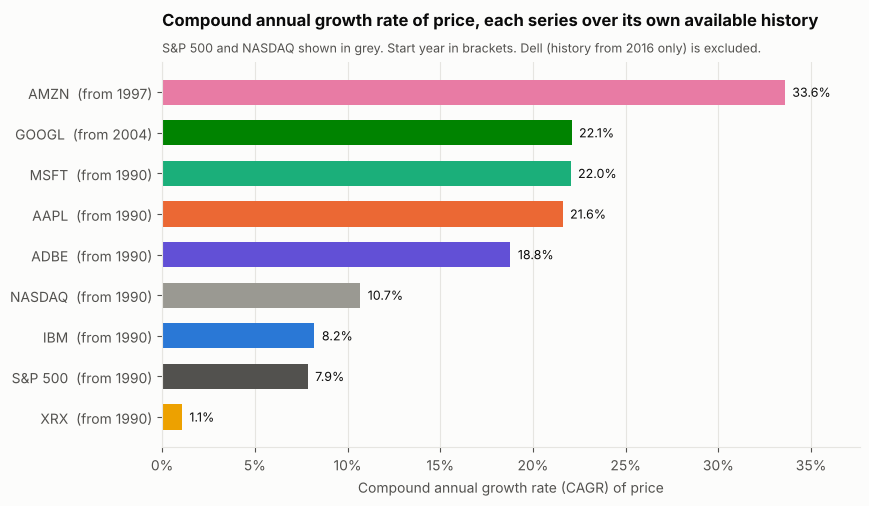

In [14]:
fig = viz.plot_cagr_bars(kpi_full.drop(index="DELL"),
        "Compound annual growth rate of price, each series over its own available history",
        "S&P 500 and NASDAQ shown in grey. Start year in brackets. Dell (history from 2016 only) is excluded.")
viz.save_figure(fig, "fig01_cagr_full_history.png", FIG_DIR, close=False)
plt.show()

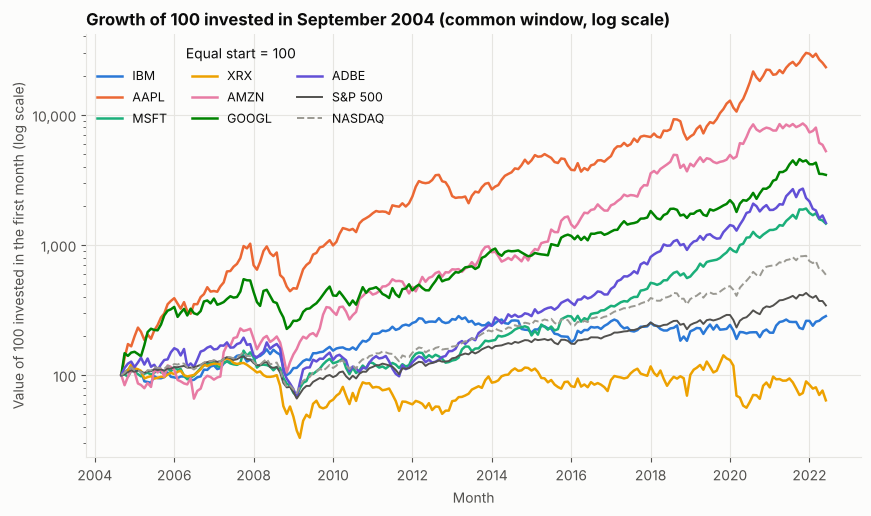

,Value of 100 in June 2022
AAPL,23230
AMZN,5257
GOOGL,3454
ADBE,1479
MSFT,1459
NASDAQ,589
S&P 500,343
IBM,284
XRX,64


In [15]:
fig = viz.plot_growth_of_100(window, "Growth of 100 invested in September 2004 (common window, log scale)")
viz.save_figure(fig, "fig02_growth_of_100_common_window.png", FIG_DIR, close=False)
plt.show()
final_values = (window.iloc[-1] / window.iloc[0] * 100).round(0).astype(int).rename("Value of 100 in June 2022")
final_values.index = [viz.label(i) for i in final_values.index]
final_values.sort_values(ascending=False).to_frame()

**Observed facts (common window, 17.75 years).**
* Apple grew fastest (CAGR **35.9 %**), then Amazon (**25.0 %**) and Alphabet (**22.1 %**). Adobe (**16.4 %**) and Microsoft (**16.3 %**) were almost equal. IBM grew **6.1 %** a year, below the S&P 500 (**7.2 %**). Xerox lost value (**−2.5 %** a year; a 100 investment fell to about **64**).
* Five of the seven holdings grew faster than the NASDAQ Composite (**10.5 %**).
* Over the full history, Microsoft (**22.0 %**), Apple (**21.6 %**) and Adobe (**18.8 %**) grew far faster than the S&P 500 (**7.9 %**) and NASDAQ (**10.7 %**); IBM (**8.2 %**) was close to the S&P 500; Xerox managed **1.1 %**. Amazon has grown **33.6 %** a year since June 1997.

**Interpretation.** Growth was very unequal. Three holdings (Apple, Amazon, Alphabet) account for the largest gains; two (IBM, Xerox) did not beat the broad market.

**Limitations.** These companies are well-known names that exist today, so the set is likely to look better than a random selection of 1990 technology companies (survivorship bias). If the file's stock prices are adjusted for dividends but the index levels are not, the stocks have a small built-in advantage over the indices. The causes of each company's performance are not in this dataset.

### Q2. How risky was each holding?
**Method:** annualised volatility, maximum drawdown (Fig 4), and the spread of monthly returns (Fig 5 box plot, Fig 6 histograms). Fig 3 plots growth against volatility.

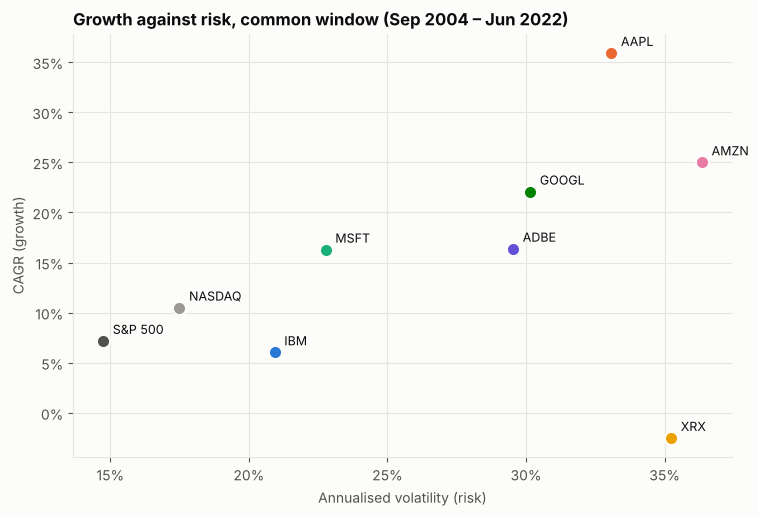

In [16]:
fig = viz.plot_risk_return(kpi_common, "Growth against risk, common window (Sep 2004 – Jun 2022)")
viz.save_figure(fig, "fig03_risk_vs_return.png", FIG_DIR, close=False)
plt.show()

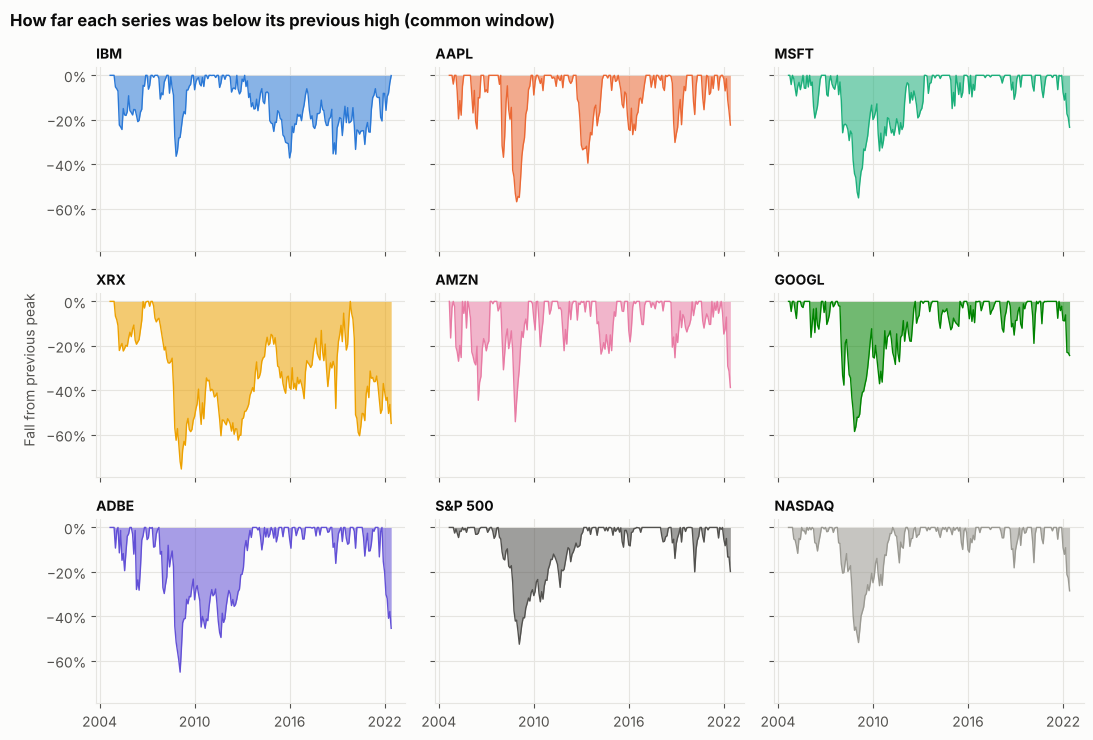

,Max drawdown (%),Peak month,Trough month
IBM,-37.2,2013-03,2016-01
AAPL,-56.9,2007-12,2008-12
MSFT,-55.2,2007-10,2009-02
XRX,-75.5,2007-05,2009-03
AMZN,-54.2,2007-09,2008-11
GOOGL,-58.6,2007-10,2008-11
ADBE,-65.1,2007-10,2009-02
S&P 500,-52.6,2007-10,2009-02
NASDAQ,-51.8,2007-10,2009-02


In [17]:
fig = viz.plot_drawdowns(window, "How far each series was below its previous high (common window)")
viz.save_figure(fig, "fig04_drawdowns.png", FIG_DIR, close=False)
plt.show()

dd = kpi_common[["max_drawdown", "drawdown_peak", "drawdown_trough"]].copy()
dd["max_drawdown"] = (dd["max_drawdown"] * 100).round(1)
dd["drawdown_peak"] = dd["drawdown_peak"].dt.strftime("%Y-%m")
dd["drawdown_trough"] = dd["drawdown_trough"].dt.strftime("%Y-%m")
dd.index = [viz.label(i) for i in dd.index]
dd.columns = ["Max drawdown (%)", "Peak month", "Trough month"]
dd

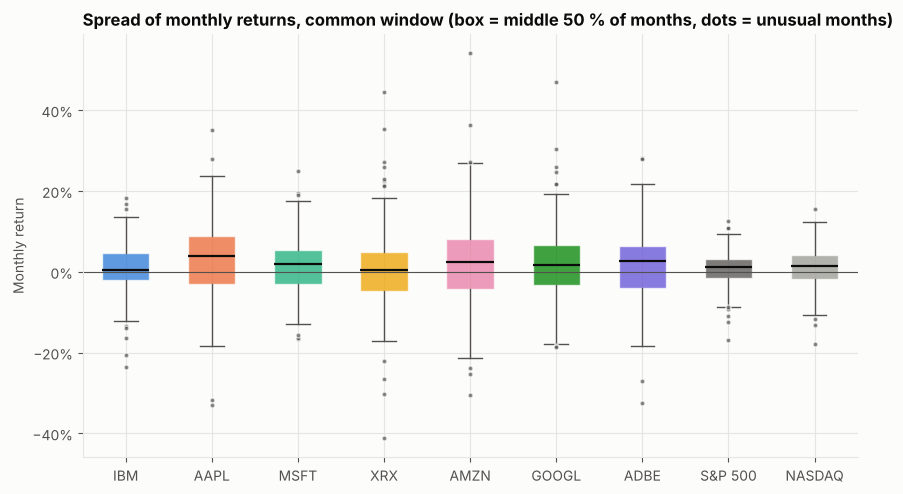

In [18]:
fig = viz.plot_return_boxplot(ret, "Spread of monthly returns, common window (box = middle 50 % of months, dots = unusual months)")
viz.save_figure(fig, "fig05_monthly_return_boxplot.png", FIG_DIR, close=False)
plt.show()

Largest fall over each series' FULL history:


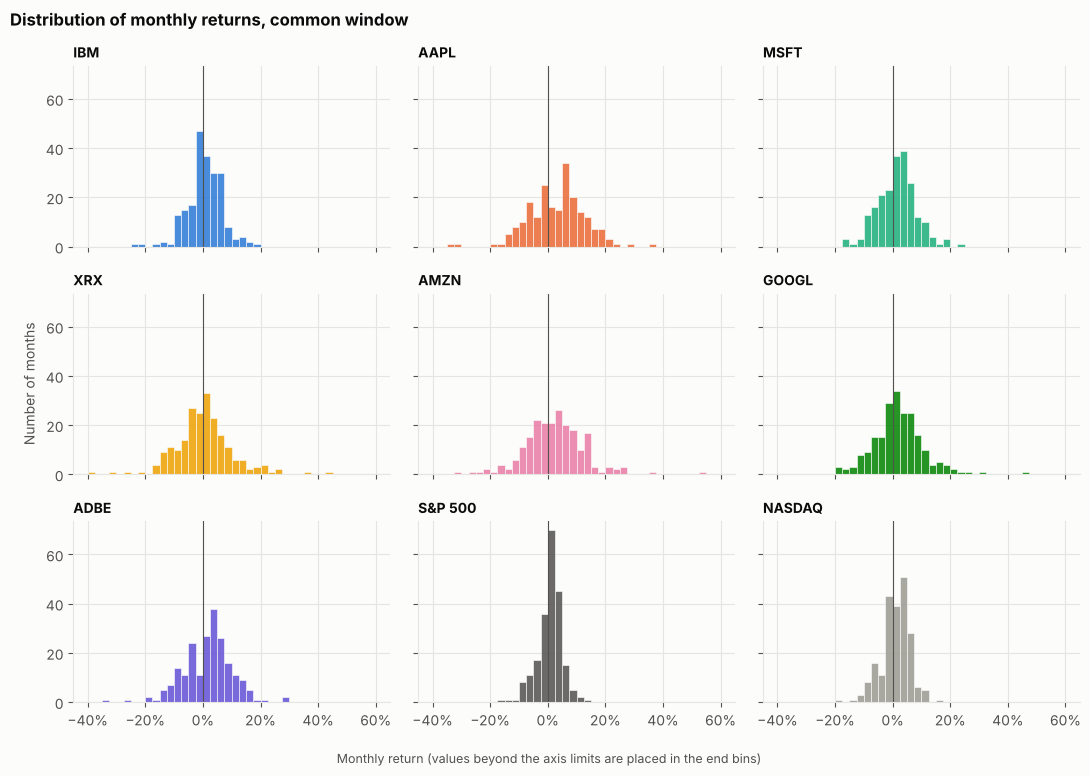

,Max drawdown (%),Peak month,Trough month
IBM,-62.8,1991-02,1993-09
AAPL,-79.6,1991-03,1997-12
MSFT,-66.9,1999-12,2009-02
XRX,-92.1,1999-01,2000-12
AMZN,-93.1,1999-03,2001-09
GOOGL,-58.6,2007-10,2008-11
ADBE,-75.3,2000-09,2002-09
S&P 500,-52.6,2007-10,2009-02
NASDAQ,-75.0,2000-02,2002-09


In [19]:
fig = viz.plot_return_histograms(ret, "Distribution of monthly returns, common window")
viz.save_figure(fig, "fig06_monthly_return_histograms.png", FIG_DIR, close=False)
plt.show()

full_dd = kpi_full[["max_drawdown", "drawdown_peak", "drawdown_trough"]].drop(index="DELL").copy()
full_dd["max_drawdown"] = (full_dd["max_drawdown"] * 100).round(1)
full_dd["drawdown_peak"] = full_dd["drawdown_peak"].dt.strftime("%Y-%m")
full_dd["drawdown_trough"] = full_dd["drawdown_trough"].dt.strftime("%Y-%m")
full_dd.index = [viz.label(i) for i in full_dd.index]
full_dd.columns = ["Max drawdown (%)", "Peak month", "Trough month"]
print("Largest fall over each series' FULL history:")
full_dd

**Observed facts.**
* Volatility (common window): S&P 500 **14.7 %**, NASDAQ **17.5 %**; the holdings ranged from **20.9 %** (IBM) to **36.3 %** (Amazon). Xerox (**35.2 %**) and Apple (**33.1 %**) were also high.
* Largest falls (common window): Xerox **−75.5 %**, Adobe **−65.1 %**, Alphabet **−58.6 %**, Apple **−56.9 %**, Microsoft **−55.2 %**, Amazon **−54.2 %**, against **−52.6 %** for the S&P 500. IBM's largest fall (**−37.2 %**) was the smallest. Six of the seven holdings fell further than the S&P 500 at their worst point.
* Six holdings reached their peak in 2007 and their low between November 2008 and March 2009. IBM's largest fall was a different, slower episode (March 2013 to January 2016).
* Over the full history, Amazon fell **93.1 %** (March 1999 to September 2001) and Xerox **92.1 %** (January 1999 to December 2000) before the data show any recovery.
* Box plot and histograms: all holdings have a positive median monthly return, but their monthly returns are much more spread out than the indices', with long tails on both sides.

**Interpretation.** High growth and high risk came together. Apple's, Amazon's and Alphabet's gains required living through falls of more than half their value. This is a statement about past prices; it does not explain *why* the falls happened.

**Limitation.** Drawdowns use month-end prices; daily prices would show deeper short-lived falls.

### Q3. Which holdings delivered the most growth for the risk taken?
**Method:** return-to-risk ratio = CAGR ÷ annualised volatility (risk-free rate assumed 0). Fig 3 above shows the same information: points high and to the left are better.

In [20]:
r2r = kpi_common["return_to_risk"].astype(float).sort_values(ascending=False)
r2r.index = [viz.label(i) for i in r2r.index]
r2r.round(2).rename("Return / risk (common window)").to_frame()

,Return / risk (common window)
AAPL,1.09
GOOGL,0.73
MSFT,0.72
AMZN,0.69
NASDAQ,0.60
ADBE,0.56
S&P 500,0.49
IBM,0.29
XRX,-0.07


**Observed facts.** Apple had the best ratio (**1.09**), followed by Alphabet (**0.73**), Microsoft (**0.72**) and Amazon (**0.69**). NASDAQ scored **0.60**, Adobe **0.56**, the S&P 500 **0.49**, IBM **0.29** and Xerox **−0.07**.

**Interpretation.** Taking more volatility did not guarantee a better outcome: Xerox was among the most volatile holdings but grew negatively. Amazon's very high growth came with the highest volatility, so its ratio is below Alphabet's and Microsoft's. Apple stands out because its growth was much larger than its risk. The ratio uses a 0 % risk-free rate, so absolute values are simplified; the *ranking* is what matters here.

### Q4. How strongly does each holding follow the market?
**Method:** beta against the S&P 500 (Fig 7) and a scatter of each holding's monthly return against the market's monthly return, with a fitted line whose slope is the beta (Fig 8).

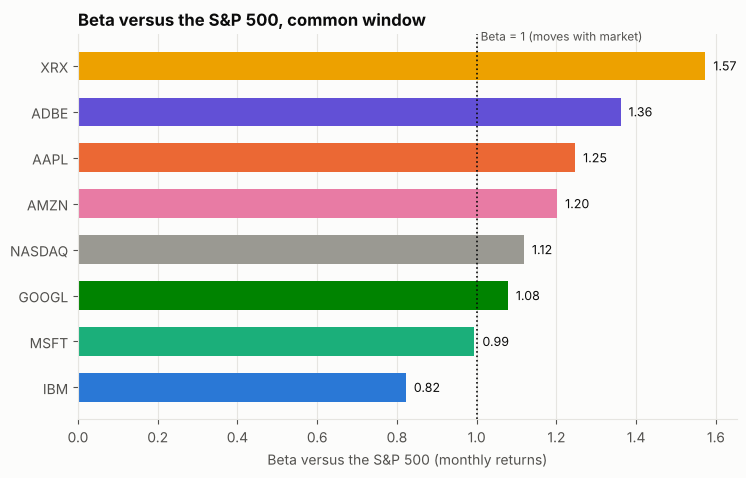

In [21]:
fig = viz.plot_beta_bars(kpi_common.drop(index=MARKET), "Beta versus the S&P 500, common window")
viz.save_figure(fig, "fig07_beta_vs_market.png", FIG_DIR, close=False)
plt.show()

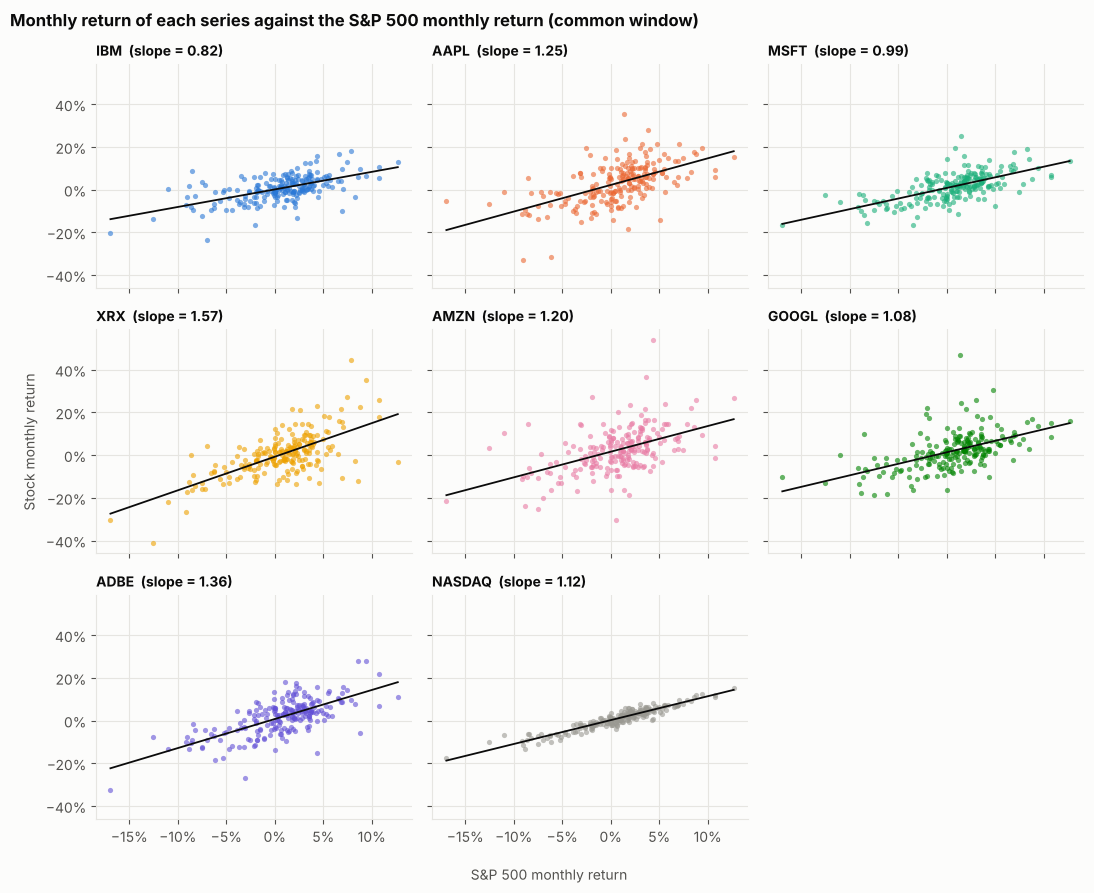

,beta_vs_market,corr_with_market,share of monthly variation explained (corr^2)
IBM,0.82,0.58,0.34
AAPL,1.25,0.56,0.31
MSFT,0.99,0.64,0.41
XRX,1.57,0.66,0.43
AMZN,1.20,0.49,0.24
GOOGL,1.08,0.53,0.28
ADBE,1.36,0.68,0.46


In [22]:
fig = viz.plot_beta_scatter(ret, MARKET, "Monthly return of each series against the S&P 500 monthly return (common window)")
viz.save_figure(fig, "fig08_beta_scatter.png", FIG_DIR, close=False)
plt.show()

relation = kpi_common.loc[CORE, ["beta_vs_market", "corr_with_market"]].astype(float).copy()
relation["share of monthly variation explained (corr^2)"] = relation["corr_with_market"] ** 2
relation.index = [viz.label(i) for i in relation.index]
relation.round(2)

**Observed facts.** Beta ranged from **0.82** (IBM) and **0.99** (Microsoft) up to **1.36** (Adobe) and **1.57** (Xerox); Apple **1.25**, Amazon **1.20**, Alphabet **1.08**. Correlations with the S&P 500 were between **0.49** (Amazon) and **0.68** (Adobe). Squared, this means the market explains roughly **24 %** (Amazon) to **46 %** (Adobe) of each holding's monthly movement.

**Interpretation.** Most holdings amplify market moves (beta above 1); only IBM and, marginally, Microsoft were at or below the market. Because the market explains less than half of each holding's movement, a large part of the risk is specific to the company. Xerox had the highest beta and still lost value, so high market sensitivity was not rewarded in this sample.

**Limitation.** Beta and correlation describe how returns moved together in the past; they do not show that the market *causes* a company's movements.

### Q5. How did the holdings behave in past market-stress periods?
**Method:** three stress windows were fixed *in advance*, chosen as well-known market episodes, not selected after seeing the results: dot-com (Jan 2000 – Dec 2002), financial crisis (Oct 2007 – Mar 2009) and the early-2022 slide (Dec 2021 – Jun 2022). For each window the table shows the **largest fall from a high reached inside that window**. Alphabet did not yet have a price in the first window.

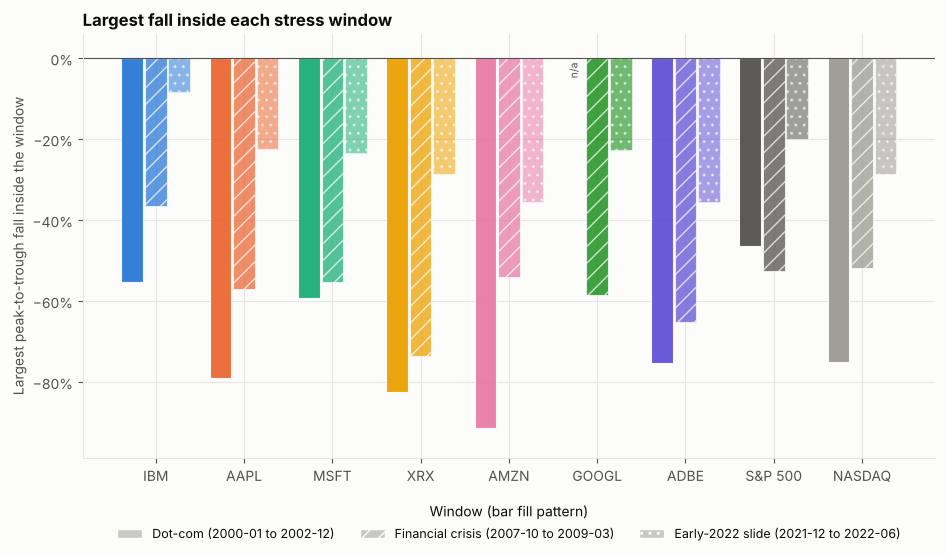

,Dot-com (2000-01 to 2002-12),Financial crisis (2007-10 to 2009-03),Early-2022 slide (2021-12 to 2022-06)
IBM,-55.3,-36.5,-8.3
AAPL,-78.9,-56.9,-22.4
MSFT,-59.2,-55.2,-23.4
XRX,-82.5,-73.4,-28.5
AMZN,-91.3,-53.9,-35.6
GOOGL,NaN,-58.6,-22.7
ADBE,-75.3,-65.1,-35.5
S&P 500,-46.3,-52.6,-19.8
NASDAQ,-75.0,-51.8,-28.5


In [23]:
WINDOWS = {
    "Dot-com (2000-01 to 2002-12)": ("2000-01", "2002-12"),
    "Financial crisis (2007-10 to 2009-03)": ("2007-10", "2009-03"),
    "Early-2022 slide (2021-12 to 2022-06)": ("2021-12", "2022-06"),
}
stress = kpi.downturn_table(prices[CORE + INDICES], WINDOWS)

fig = viz.plot_downturns(stress, "Largest fall inside each stress window")
viz.save_figure(fig, "fig09_stress_windows.png", FIG_DIR, close=False)
plt.show()

shown = (stress * 100).round(1)
shown.index = [viz.label(i) for i in shown.index]
shown

In [24]:
# Do holdings with a higher beta fall further? (rank correlation; only 6-7 points, so descriptive)
rows = []
for name, col in zip(["Dot-com", "Financial crisis", "Early 2022"], stress.columns):
    d = pd.concat([kpi_common.loc[CORE, "beta_vs_market"].astype(float), -stress.loc[CORE, col]], axis=1).dropna()
    r = stats.spearmanr(d.iloc[:, 0], d.iloc[:, 1])
    rows.append({"Window": name, "Holdings used": len(d), "Spearman rho (beta vs size of fall)": round(r.statistic, 2), "p-value": round(r.pvalue, 3)})
pd.DataFrame(rows)

,Window,Holdings used,Spearman rho (beta vs size of fall),p-value
0,Dot-com,6,0.60,0.208
1,Financial crisis,7,0.82,0.023
2,Early 2022,7,0.54,0.215


**Observed facts.**
* Every holding and both indices fell in every window.
* Dot-com window: Amazon **−91.3 %**, Xerox **−82.5 %**, Apple **−78.9 %**, Adobe **−75.3 %**, Microsoft **−59.2 %**, IBM **−55.3 %**, against **−46.3 %** for the S&P 500 and **−75.0 %** for NASDAQ.
* Financial-crisis window: falls ranged from **−36.5 %** (IBM) to **−73.4 %** (Xerox); S&P 500 **−52.6 %**.
* Early 2022: S&P 500 **−19.8 %**; Amazon **−35.6 %**, Adobe **−35.5 %**, Xerox **−28.5 %**, Microsoft **−23.4 %**, Alphabet **−22.7 %**, Apple **−22.4 %**, IBM **−8.3 %**. (The window ends in June 2022, a partial month.)
* In the financial-crisis window, holdings with a higher beta fell further (Spearman ρ = **0.82**, p = **0.023**, 7 holdings). In the dot-com and 2022 windows the relationship was in the same direction but weaker and not statistically clear (ρ = **0.60**, p = **0.208** and ρ = **0.54**, p = **0.215**).

**Interpretation.** None of the holdings protected the club in a market-wide fall; the least affected (IBM) still lost more than a third of its value in the financial-crisis window. A higher beta was *associated* with deeper falls, which fits the idea that beta gives a rough warning of stress behaviour, but with so few holdings this is only a hypothesis to test further.

### Q6. Does holding all seven together reduce risk?
**Method:** correlation matrix of monthly returns (Fig 10); a hypothetical **equal-weight basket** that holds the seven stocks in equal parts and is rebalanced monthly (Fig 12). The basket ignores trading costs and taxes.

Lowest-correlated pairs among the 7 holdings:
XRX  AMZN     0.25
IBM  GOOGL    0.28
XRX  GOOGL    0.30
Highest-correlated pair among the 7 holdings:
MSFT  ADBE    0.53


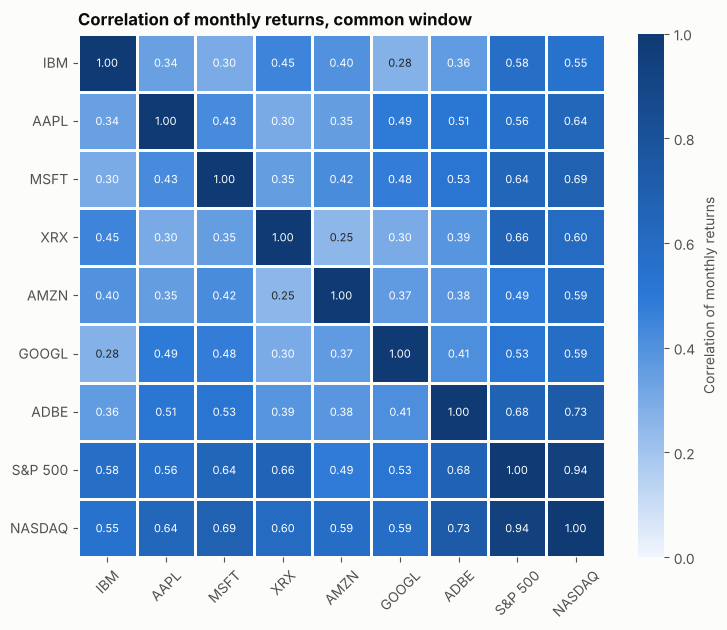

In [25]:
corr = ret.corr()
fig = viz.plot_correlation_heatmap(corr, "Correlation of monthly returns, common window")
viz.save_figure(fig, "fig10_correlation_heatmap.png", FIG_DIR, close=False)
plt.show()

core_corr = ret_core.corr()
pairs = core_corr.where(np.triu(np.ones(core_corr.shape), 1).astype(bool)).stack().dropna().sort_values()
print("Lowest-correlated pairs among the 7 holdings:")
print(pairs.head(3).round(2).to_string())
print("Highest-correlated pair among the 7 holdings:")
print(pairs.tail(1).round(2).to_string())

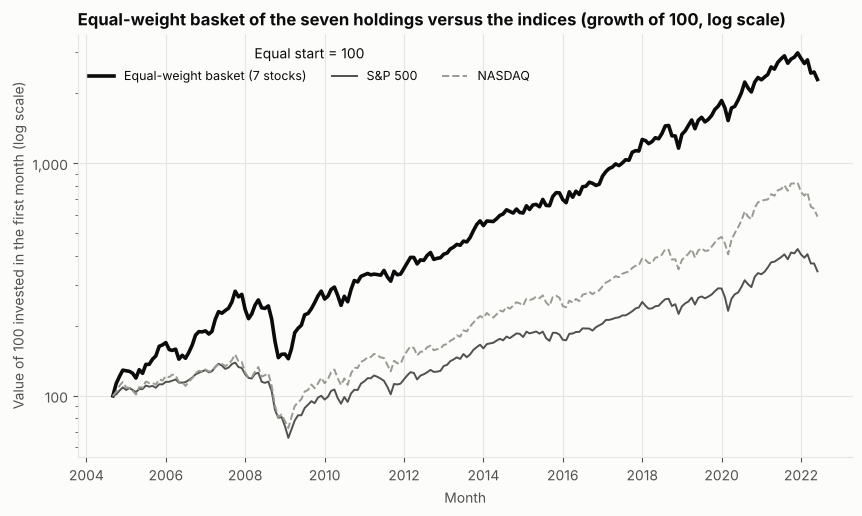

,Result
Average pairwise correlation (all months),0.386
Average pairwise correlation (financial-crisis window),0.465
Months in the crisis window,18.000
Average volatility of the 7 single stocks,0.297
Volatility of the equal-weight basket,0.204
Basket volatility is lower by,0.312
Basket CAGR,0.193
Basket maximum drawdown,-0.487
S&P 500 maximum drawdown,-0.526
Basket return / risk,0.944


In [26]:
ew_ret = kpi.equal_weight_portfolio(ret_core)
ew_index = kpi.index_from_returns(ew_ret)

basket = pd.DataFrame({"EQUAL_WEIGHT": ew_index,
                       "^GSPC": window["^GSPC"], "^IXIC": window["^IXIC"]})
fig = viz.plot_growth_of_100(basket, "Equal-weight basket of the seven holdings versus the indices (growth of 100, log scale)")
viz.save_figure(fig, "fig12_equal_weight_basket.png", FIG_DIR, close=False)
plt.show()

avg_single_vol = kpi_common.loc[CORE, "ann_volatility"].astype(float).mean()
ew_vol = kpi.annualised_volatility(ew_ret)
crisis_start, crisis_end = WINDOWS["Financial crisis (2007-10 to 2009-03)"]
div = pd.Series({
    "Average pairwise correlation (all months)": kpi.mean_pairwise_correlation(ret_core),
    "Average pairwise correlation (financial-crisis window)": kpi.mean_pairwise_correlation(ret_core.loc[crisis_start:crisis_end]),
    "Months in the crisis window": len(ret_core.loc[crisis_start:crisis_end]),
    "Average volatility of the 7 single stocks": avg_single_vol,
    "Volatility of the equal-weight basket": ew_vol,
    "Basket volatility is lower by": 1 - ew_vol / avg_single_vol,
    "Basket CAGR": kpi.cagr(ew_index),
    "Basket maximum drawdown": kpi.max_drawdown(ew_index)[0],
    "S&P 500 maximum drawdown": kpi_common.loc[MARKET, "max_drawdown"],
    "Basket return / risk": kpi.cagr(ew_index) / ew_vol,
}, name="Result")
div.round(3).to_frame()

**Observed facts.** The seven holdings are only moderately correlated with each other (average pairwise correlation **0.39**; lowest pairs Xerox–Amazon **0.25**, IBM–Alphabet **0.28**, Xerox–Alphabet **0.30**). The equal-weight basket had volatility of **20.4 %**, which is about **31 %** lower than the **29.7 %** average volatility of the seven single stocks. Its CAGR was **19.3 %**, a little above the simple average of the seven single-stock CAGRs (**17.0 %**); its largest fall was **−48.7 %** (S&P 500: **−52.6 %**) and its return-to-risk ratio **0.94**. In the 18 months of the financial-crisis window the average pairwise correlation rose to **0.47**.

**Interpretation.** Combining the seven reduced volatility noticeably without lowering growth below the single-stock average, which supports keeping a basket rather than concentrating in a few names. But the basket still lost almost half its value at its worst point, so diversification *within* technology shares did not remove the risk of a large fall. The higher correlation in the crisis window is consistent with diversification weakening when markets fall, but 18 months is a small sample.

**Limitations.** The basket is hypothetical (monthly rebalancing, no costs or taxes) and is measured over a period in which these particular companies did well.

### Q7. How consistent were returns from year to year?
**Method:** calendar-year return = December price ÷ previous December price − 1, for full years only (Fig 11). The partial year 2022 is excluded.

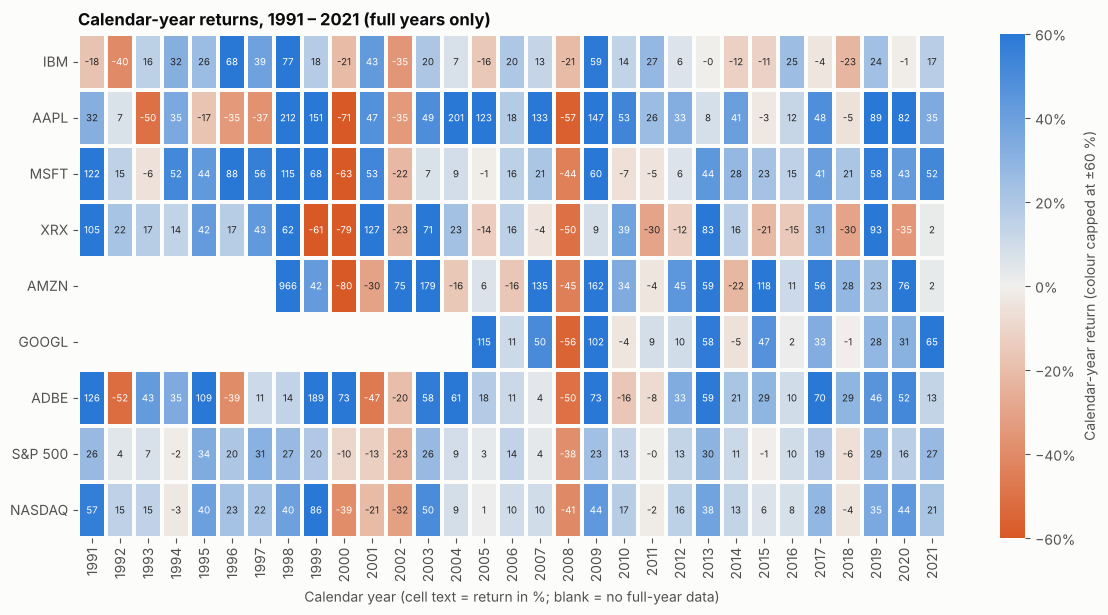

,Full years,Positive years,Share positive,Best year,Best return,Worst year,Worst return
IBM,31,19,0.613,1998,0.775,1992,-0.400
AAPL,31,22,0.710,1998,2.119,2000,-0.711
MSFT,31,24,0.774,1991,1.218,2000,-0.628
XRX,31,19,0.613,2001,1.272,2000,-0.787
AMZN,24,17,0.708,1998,9.664,2000,-0.796
GOOGL,17,13,0.765,2005,1.152,2008,-0.555
ADBE,31,24,0.774,1999,1.886,1992,-0.516
S&P 500,31,23,0.742,1995,0.341,2008,-0.385
NASDAQ,31,24,0.774,1999,0.856,2008,-0.405


In [27]:
yearly = kpi.calendar_year_returns(prices.drop(columns="DELL"))
fig = viz.plot_yearly_heatmap(yearly, "Calendar-year returns, 1991 – 2021 (full years only)")
viz.save_figure(fig, "fig11_calendar_year_returns.png", FIG_DIR, close=False)
plt.show()

consistency = pd.DataFrame({
    "Full years": yearly.notna().sum(),
    "Positive years": (yearly > 0).sum(),
    "Share positive": (yearly > 0).sum() / yearly.notna().sum(),
    "Best year": yearly.idxmax(),
    "Best return": yearly.max(),
    "Worst year": yearly.idxmin(),
    "Worst return": yearly.min(),
})
consistency.index = [viz.label(i) for i in consistency.index]
consistency.round(3)

**Observed facts.** Microsoft and Adobe finished higher in **24 of 31** years (**77.4 %**), Alphabet in **13 of 17** (**76.5 %**), Apple in **22 of 31** (**71.0 %**), Amazon in **17 of 24** (**70.8 %**), IBM and Xerox in **19 of 31** (**61.3 %**). The S&P 500 was up in **23 of 31** years (**74.2 %**). The worst single years were Amazon **−79.6 %** (2000), Xerox **−78.7 %** (2000) and Apple **−71.1 %** (2000); the best was Amazon's **+966 %** in 1998.

**Interpretation.** Even the strongest holdings lost money in roughly one year in four, and the worst years were severe and clustered around 2000 and 2008 (see Fig 11). The holdings were not more reliable year to year than the S&P 500 (Microsoft and Adobe only slightly better); their advantage came from larger gains in good years. Different holdings have different numbers of full years, so shares are not perfectly comparable.

### Q8. Which months were unusual, and when?
**Method:** a month is flagged if its return is more than 3 standard deviations away from that series' own average monthly return (z-score), over the common window.

In [28]:
outliers = kpi.outlier_months(ret)
total_returns_checked = int(ret.iloc[1:].notna().sum().sum())
print(f"{len(outliers)} unusual months out of {total_returns_checked} monthly returns ({len(outliers) / total_returns_checked:.1%})")

shown = outliers.copy()
shown["month"] = shown["month"].dt.strftime("%Y-%m")
shown["return"] = (shown["return"] * 100).round(1).astype(str) + "%"
shown["z_score"] = shown["z_score"].round(1)
shown["ticker"] = shown["ticker"].map(viz.label)
display(shown.reset_index(drop=True))

by_year = outliers["month"].dt.year.value_counts().sort_index()
print("Unusual months by year:", by_year.to_dict())

21 unusual months out of 1917 monthly returns (1.1%)
Unusual months by year: {2004: 2, 2005: 1, 2006: 2, 2007: 2, 2008: 7, 2009: 3, 2018: 1, 2019: 1, 2020: 2}


,ticker,month,return,z_score
0,GOOGL,2004-10,47.1%,5.2
1,AMZN,2007-04,54.1%,4.9
2,XRX,2019-01,44.6%,4.4
3,S&P 500,2008-10,-16.9%,-4.1
4,XRX,2020-03,-41.2%,-4.1
5,IBM,2018-10,-23.7%,-4.0
6,ADBE,2008-10,-32.5%,-4.0
7,AAPL,2008-09,-33.0%,-3.8
8,NASDAQ,2008-10,-17.7%,-3.7
9,AAPL,2008-01,-31.7%,-3.6


**Observed facts.** **21** of **1,917** monthly returns (**1.1 %**) were beyond ±3 standard deviations. **10** of the 21 fall in 2008–2009 (7 in 2008, 3 in 2009), including October 2008, when IBM, Adobe, the S&P 500 and NASDAQ were all flagged. The largest were Alphabet **+47.1 %** (October 2004, its second month in the data), Amazon **+54.1 %** (April 2007), Xerox **+44.6 %** (January 2019) and **−41.2 %** (March 2020), and IBM **−23.7 %** (October 2018).

**Interpretation.** Extreme months cluster in the financial crisis, which supports stress testing. The isolated company-specific extremes (for example Xerox in 2019 and 2020, IBM in 2018) are **hypotheses to investigate**: the dataset contains no information about earnings releases, corporate actions or news, so it cannot explain them.

## 10. Evidence-based findings and business insights register
*Observed facts* come directly from the calculations above. *Interpretations* are explanations supported by the analysis. *Hypotheses* need further investigation. No causes are claimed where the data cannot show them.

| ID | Business question | Finding (observed) | Numerical evidence | Source | Interpretation / potential business impact | Confidence or limitation | Suggested follow-up |
|---|---|---|---|---|---|---|---|
| F1 | Q1 | Growth was very unequal across holdings | Common-window CAGR: Apple 35.9 %, Amazon 25.0 %, Alphabet 22.1 % … IBM 6.1 %, Xerox −2.5 %; S&P 500 7.2 % | Fig 1, 2; KPI table | Three holdings produced most of the gain; two did not beat the market. Allocation to winners and laggards matters more than owning the sector. | Survivorship bias; possible adjusted-price advantage over indices | Compare with a wider list of tech companies |
| F2 | Q2 | Higher growth came with higher risk; 6 of 7 holdings fell further than the S&P 500 at their worst point | Max drawdown: Xerox −75.5 %, Adobe −65.1 % … IBM −37.2 %; S&P 500 −52.6 %. Amazon −93.1 % over full history | Fig 3, 4, 5, 6 | Large positions in these holdings expose the club to falls of more than half their value. Position sizing is a decision, not a detail. | Month-end prices understate daily falls | Test position-size caps (see R1) |
| F3 | Q3 | Return per unit of risk differed widely | Return/risk: Apple 1.09, Alphabet 0.73, Microsoft 0.72, Amazon 0.69 … IBM 0.29, Xerox −0.07; S&P 500 0.49 | Fig 3 | Taking more volatility was not automatically rewarded (Xerox). Apple earned most per unit of risk. | 0 % risk-free rate assumed; one period | Re-test with another period |
| F4 | Q4 | Most holdings amplify market moves, but market explains < half of their movement | Beta 0.82 (IBM) to 1.57 (Xerox); correlation 0.49–0.68; market explains 24 %–46 % | Fig 7, 8 | Much of the risk is company-specific, so monitoring individual companies matters. | Association, not causation | Add company-level data (earnings, news) |
| F5 | Q5 | No holding protected the club in market-wide falls; higher beta went with deeper falls in the 2007–09 crisis | Crisis-window falls −36.5 % to −73.4 %; Spearman ρ = 0.82 (p = 0.023, 7 holdings) | Fig 9 | Stress losses of more than a third should be expected in a major downturn. | Only 7 holdings; weaker in other windows (hypothesis) | Add more companies and windows |
| F6 | Q6 | Combining the seven lowered volatility by about 31 % | Basket volatility 20.4 % vs 29.7 % average single stock; basket drawdown −48.7 %; avg. correlation 0.39 (0.47 in crisis window) | Fig 10, 12 | Keeping a basket reduces risk, but a sector-wide fall still cost almost half the value. | Hypothetical basket; no costs; favourable period | Test adding assets outside the dataset |
| F7 | Q7 | Even strong holdings lost money in about one year in four | Positive years: Microsoft/Adobe 77.4 %, Alphabet 76.5 %, S&P 500 74.2 %, IBM/Xerox 61.3 % | Fig 11 | Expect losing years; do not assume steady annual gains. | Different numbers of full years | – |
| F8 | Q8 | Extreme months cluster in the financial crisis | 21 of 1,917 months beyond ±3 SD; 10 in 2008–09 | Outlier table | Supports regular stress testing. Isolated company extremes (Xerox 2019/2020, IBM 2018) need explanation. | Causes are **not** in the data (hypotheses) | Match flagged months to company events |

## 11. Executive summary
**Business problem.** An (assumed) technology-focused investment club asked which of its seven long-held technology shares created value, at what risk, and whether holding them together reduces risk.

**Data.** Real monthly Yahoo Finance prices from January 1990 to June 2022 (390 months after cleaning) for IBM, Apple, Microsoft, Xerox, Amazon, Alphabet and Adobe, plus the S&P 500 and NASDAQ Composite. Dell is in the file but has only 70 months of history. Comparisons use a common window of 17.75 years (September 2004 – June 2022).

**Key metrics (common window).** Apple CAGR 35.9 %, Amazon 25.0 %, Alphabet 22.1 %, Adobe 16.4 %, Microsoft 16.3 %, IBM 6.1 %, Xerox −2.5 %, against 7.2 % (S&P 500) and 10.5 % (NASDAQ). Annual volatility ranged from 20.9 % to 36.3 % for the holdings, against 14.7 % for the S&P 500.

**Major findings.**
1. Growth was concentrated in Apple, Amazon and Alphabet; IBM and Xerox did not beat the market.
2. Growth came with risk: six of seven holdings fell further than the S&P 500 at their worst point (Xerox −75.5 %, Adobe −65.1 %).
3. Every holding fell in every market-stress window tested; no holding was a safe haven.
4. Market movements explain only 24 %–46 % of each holding's monthly changes, so company-specific risk is large.
5. An equal-weight basket had about 31 % lower volatility than the average single stock, but still fell 48.7 % at its worst.

**Overall conclusion.** Holding all seven reduced risk without lowering growth below the single-stock average, but position sizes, stress testing and a review of the weakest holdings (Xerox, IBM) are the main decisions the data point to.

**Important limitations.** Prices only (no financials); survivorship bias; unclear price adjustments; monthly data; a partial final month; findings describe the past and do not prove causes or predict the future.

## 12. Actionable recommendations
These follow from the findings above. No financial return is promised; "expected direction" means what the evidence suggests, to be tested.

| ID | Supporting finding | Proposed action | Reason | Priority | Suggested owner | Expected direction of impact | KPI to measure success | Time horizon | Validation / experiment plan | Risks and assumptions |
|---|---|---|---|---|---|---|---|---|---|---|
| R1 | F2, F4 | Set a maximum weight for each holding, with lower caps for the highest-risk names (Xerox, Adobe, Amazon, Apple) | The four named holdings fell 54 %–76 % at their worst point, so large positions create large losses | **High** | Portfolio manager | Smaller worst-case losses | Portfolio maximum drawdown; share of total risk from the largest holding | Next committee meeting | Back-test several cap levels on this dataset and compare drawdown and CAGR | Caps may reduce gains; back-test uses past data only |
| R2 | F6 | Keep a diversified basket of all seven instead of concentrating in a few | Equal-weight basket volatility was about 31 % lower than the average single stock | **High** | Investment committee chair | Lower volatility without lowering growth below the single-stock average | Portfolio volatility; average pairwise correlation | Ongoing | Compare the basket with concentrated alternatives on out-of-sample months | The period favoured these companies; diversification weakens in crises |
| R3 | F5, F8 | Add a regular stress-test report using the three windows (dot-com, 2007–09, 2022) | Every holding fell in every window; extreme months cluster in crises | **High** | Risk manager | Earlier awareness of downside | Largest fall in each window per holding | Monthly / quarterly | Re-run the stress table whenever holdings change | Past crises may not resemble the next one |
| R4 | F1, F3 | Put Xerox on a formal watch list and review IBM; decide with company information, not prices alone | Both grew below the S&P 500 (IBM 6.1 %, Xerox −2.5 % vs 7.2 %) and Xerox combined high beta with a loss | **Medium** | Portfolio manager | Better use of capital if weak positions are reduced or explained | Return/risk versus S&P 500 over the next review | One quarter | Gather fundamentals (revenue, earnings, outlook) and compare with peers | Past weakness may not continue; price data cannot explain it |
| R5 | F4, F8 | Investigate the flagged unusual months (for example Xerox 2019/2020, IBM 2018) against company events | The data cannot explain company-specific extremes | **Medium** | Risk analyst | Clarifies which risks are company-specific | Share of flagged months explained by events | One quarter | Match each flagged month with earnings dates and corporate actions | Event data must be sourced separately |
| R6 | All | Improve the data: daily prices, dividends, trading volume, confirmed price adjustments, a wider set of companies | Current data cannot show causes and may be biased toward survivors | **Medium** | Data analyst | More reliable conclusions | Data coverage; change in findings after refresh | One to two months | Re-run this notebook on the richer data and compare findings | Additional data may cost money or need licences |

## 13. Conclusions and limitations

**Conclusions.**
* Between 2004 and 2022 the seven holdings differed greatly: Apple, Amazon and Alphabet delivered the largest growth, IBM and Xerox did not beat the market.
* Higher growth came with higher volatility and deeper falls; no holding protected against market-wide declines.
* A diversified basket of all seven lowered volatility by about 31 % compared with the average single stock, yet still suffered a fall of nearly half its value.
* The most decision-relevant actions are position-size limits, stress-test reporting and a fundamentals review of the weakest holdings.

**Limitations.**
1. **Only prices.** There is no revenue, profit, volume, dividend or company news, so causes cannot be identified and no profit-based KPIs are calculated.
2. **Survivorship and selection bias.** The companies are well-known firms that still exist; results are likely better than a random 1990 technology selection.
3. **Unclear adjustments.** The file does not state whether prices are adjusted for splits and dividends. Very low early prices (for example Apple at about 0.24 in 1990) suggest adjusted stock prices, while index levels are price-only, so stocks may have a small built-in advantage over the indices. Currency is assumed to be US dollars.
4. **Monthly data.** Daily prices would show deeper short-term falls and more extreme days.
5. **Partial final month.** The June 2022 value is as of 28 June 2022.
6. **Short and uneven histories.** Alphabet starts in 2004 and Dell in 2016; Dell is excluded from comparisons.
7. **Small samples.** Seven holdings and three stress windows; the statistical tests are descriptive.
8. **Association, not causation**, and the analysis describes the past, not the future.
9. **Assumed stakeholders and organisation**; the data are not from a real investment club.

**Future work.** Daily data; dividends and fundamentals; more companies (including ones that were delisted); more stress windows; testing the recommendations by back-test.

## 14. References
1. Yahoo Finance. Historical price data. <https://finance.yahoo.com> (source named in `Stocks.csv`).
2. Matplotlib development team. `matplotlib.cbook.get_sample_data` and the `sample_data` folder, <https://matplotlib.org>.
3. McKinney, W. (2010). Data structures for statistical computing in Python. *Proceedings of the 9th Python in Science Conference*.
4. Harris, C. R., et al. (2020). Array programming with NumPy. *Nature*, 585, 357–362.
5. Virtanen, P., et al. (2020). SciPy 1.0: fundamental algorithms for scientific computing in Python. *Nature Methods*, 17, 261–272.
6. Hunter, J. D. (2007). Matplotlib: A 2D graphics environment. *Computing in Science & Engineering*, 9(3), 90–95.
7. Waskom, M. L. (2021). seaborn: statistical data visualization. *Journal of Open Source Software*, 6(60), 3021.

## 15. Verification: every quoted number is re-calculated
The cell below re-computes each number quoted in the text above and stops with an error if any does not match after rounding. A silent run (followed by the success message) means all quoted numbers agree with the data.

In [29]:
kc, kf = kpi_common.astype(float, errors="ignore"), kpi_full
pct = lambda x: round(float(x) * 100, 1)
claims = []   # (description, calculated value, value quoted in the text)
def claim(name, calculated, quoted): claims.append((name, calculated, quoted))

# Data quality
claim("rows raw", len(raw), 524); claim("rows clean", len(prices), 390)
claim("empty rows", q["empty_rows"], 133); claim("empty rows share %", round(q["empty_rows"] / len(raw) * 100, 1), 25.4)
claim("missing after cleaning", after_missing, 585)
for t, n in {"AMZN": 89, "GOOGL": 176, "DELL": 320}.items(): claim(f"missing {t}", int(prices[t].isna().sum()), n)
claim("Dell months", int(prices["DELL"].notna().sum()), 70)
claim("common window months", len(window), 214)
# Q1 CAGR (common window)
for t, v in {"AAPL": 35.9, "AMZN": 25.0, "GOOGL": 22.1, "ADBE": 16.4, "MSFT": 16.3, "IBM": 6.1, "XRX": -2.5, "^GSPC": 7.2, "^IXIC": 10.5}.items():
    claim(f"CAGR {t}", pct(kc.loc[t, "cagr"]), v)
claim("XRX value of 100", round(float(window["XRX"].iloc[-1] / window["XRX"].iloc[0] * 100)), 64)
claim("holdings beating NASDAQ", int((kc.loc[CORE, "cagr"] > kc.loc["^IXIC", "cagr"]).sum()), 5)
for t, v in {"MSFT": 22.0, "AAPL": 21.6, "ADBE": 18.8, "^GSPC": 7.9, "^IXIC": 10.7, "IBM": 8.2, "XRX": 1.1, "AMZN": 33.6}.items():
    claim(f"full CAGR {t}", pct(kf.loc[t, "cagr"]), v)
# Q2
for t, v in {"^GSPC": 14.7, "^IXIC": 17.5, "IBM": 20.9, "AMZN": 36.3, "XRX": 35.2, "AAPL": 33.1}.items():
    claim(f"vol {t}", pct(kc.loc[t, "ann_volatility"]), v)
for t, v in {"XRX": -75.5, "ADBE": -65.1, "GOOGL": -58.6, "AAPL": -56.9, "MSFT": -55.2, "AMZN": -54.2, "^GSPC": -52.6, "IBM": -37.2}.items():
    claim(f"maxDD {t}", pct(kc.loc[t, "max_drawdown"]), v)
claim("holdings with deeper DD than S&P", int((kc.loc[CORE, "max_drawdown"] < kc.loc["^GSPC", "max_drawdown"]).sum()), 6)
claim("peaks in 2007 (6 holdings)", int((kc.loc[[c for c in CORE if c != "IBM"], "drawdown_peak"].dt.year == 2007).sum()), 6)
claim("IBM peak", kc.loc["IBM", "drawdown_peak"].strftime("%Y-%m"), "2013-03"); claim("IBM trough", kc.loc["IBM", "drawdown_trough"].strftime("%Y-%m"), "2016-01")
claim("AMZN full DD", pct(kf.loc["AMZN", "max_drawdown"]), -93.1); claim("XRX full DD", pct(kf.loc["XRX", "max_drawdown"]), -92.1)
claim("AMZN full DD peak", kf.loc["AMZN", "drawdown_peak"].strftime("%Y-%m"), "1999-03"); claim("AMZN full DD trough", kf.loc["AMZN", "drawdown_trough"].strftime("%Y-%m"), "2001-09")
claim("XRX full DD peak", kf.loc["XRX", "drawdown_peak"].strftime("%Y-%m"), "1999-01"); claim("XRX full DD trough", kf.loc["XRX", "drawdown_trough"].strftime("%Y-%m"), "2000-12")
troughs = kc.loc[[c for c in CORE if c != "IBM"], "drawdown_trough"]
claim("troughs between 2008-11 and 2009-03", bool(((troughs >= "2008-11-01") & (troughs <= "2009-03-01")).all()), True)
claim("median monthly return positive for all", bool((ret[CORE + INDICES].median() > 0).all()), True)
# Q3
for t, v in {"AAPL": 1.09, "GOOGL": 0.73, "MSFT": 0.72, "AMZN": 0.69, "^IXIC": 0.60, "ADBE": 0.56, "^GSPC": 0.49, "IBM": 0.29, "XRX": -0.07}.items():
    claim(f"r2r {t}", round(float(kc.loc[t, "return_to_risk"]), 2), v)
# Q4
for t, v in {"IBM": 0.82, "MSFT": 0.99, "ADBE": 1.36, "XRX": 1.57, "AAPL": 1.25, "AMZN": 1.20, "GOOGL": 1.08}.items():
    claim(f"beta {t}", round(float(kc.loc[t, "beta_vs_market"]), 2), v)
claim("corr min", round(float(kc.loc[CORE, "corr_with_market"].min()), 2), 0.49); claim("corr max", round(float(kc.loc[CORE, "corr_with_market"].max()), 2), 0.68)
claim("R2 min %", round(float(kc.loc[CORE, "corr_with_market"].min() ** 2 * 100)), 24); claim("R2 max %", round(float(kc.loc[CORE, "corr_with_market"].max() ** 2 * 100)), 46)
# Q5
st = (stress * 100).round(1)
for t, v in {"AMZN": -91.3, "XRX": -82.5, "AAPL": -78.9, "ADBE": -75.3, "MSFT": -59.2, "IBM": -55.3, "^GSPC": -46.3, "^IXIC": -75.0}.items():
    claim(f"dotcom {t}", float(st.loc[t].iloc[0]), v)
claim("crisis IBM", float(st.loc["IBM"].iloc[1]), -36.5); claim("crisis XRX", float(st.loc["XRX"].iloc[1]), -73.4); claim("crisis S&P", float(st.loc["^GSPC"].iloc[1]), -52.6)
for t, v in {"^GSPC": -19.8, "AMZN": -35.6, "ADBE": -35.5, "XRX": -28.5, "MSFT": -23.4, "GOOGL": -22.7, "AAPL": -22.4, "IBM": -8.3}.items():
    claim(f"2022 {t}", float(st.loc[t].iloc[2]), v)
claim("every window negative", bool((stress.stack().dropna() < 0).all()), True)
sp = {}
for name, col in zip(["dot", "crisis", "y22"], stress.columns):
    d = pd.concat([kc.loc[CORE, "beta_vs_market"].astype(float), -stress.loc[CORE, col]], axis=1).dropna()
    sp[name] = stats.spearmanr(d.iloc[:, 0], d.iloc[:, 1])
claim("rho crisis", round(sp["crisis"].statistic, 2), 0.82); claim("p crisis", round(sp["crisis"].pvalue, 3), 0.023)
claim("rho dot", round(sp["dot"].statistic, 2), 0.60); claim("p dot", round(sp["dot"].pvalue, 3), 0.208)
claim("rho 2022", round(sp["y22"].statistic, 2), 0.54); claim("p 2022", round(sp["y22"].pvalue, 3), 0.215)
# Q6
claim("avg pairwise corr", round(div["Average pairwise correlation (all months)"], 2), 0.39)
claim("avg pairwise corr crisis", round(div["Average pairwise correlation (financial-crisis window)"], 2), 0.47)
claim("crisis months", int(div["Months in the crisis window"]), 18)
claim("XRX-AMZN", round(float(core_corr.loc["XRX", "AMZN"]), 2), 0.25); claim("IBM-GOOGL", round(float(core_corr.loc["IBM", "GOOGL"]), 2), 0.28); claim("XRX-GOOGL", round(float(core_corr.loc["XRX", "GOOGL"]), 2), 0.30)
claim("basket vol", pct(ew_vol), 20.4); claim("avg single vol", pct(avg_single_vol), 29.7)
claim("vol reduction %", round(float(div["Basket volatility is lower by"]) * 100), 31)
claim("basket CAGR", pct(div["Basket CAGR"]), 19.3); claim("avg single CAGR", pct(kc.loc[CORE, "cagr"].mean()), 17.0); claim("basket maxDD", pct(div["Basket maximum drawdown"]), -48.7)
claim("basket r2r", round(float(div["Basket return / risk"]), 2), 0.94)
# Q7
cs = consistency
for t, (n, tot, share) in {"MSFT": (24, 31, 77.4), "ADBE": (24, 31, 77.4), "GOOGL": (13, 17, 76.5), "AAPL": (22, 31, 71.0), "AMZN": (17, 24, 70.8), "IBM": (19, 31, 61.3), "XRX": (19, 31, 61.3), "^GSPC": (23, 31, 74.2)}.items():
    claim(f"pos years {t}", (int(cs.loc[viz.label(t), "Positive years"]), int(cs.loc[viz.label(t), "Full years"]), pct(cs.loc[viz.label(t), "Share positive"])), (n, tot, share))
claim("AMZN worst", (pct(cs.loc["AMZN", "Worst return"]), int(cs.loc["AMZN", "Worst year"])), (-79.6, 2000))
claim("XRX worst", (pct(cs.loc["XRX", "Worst return"]), int(cs.loc["XRX", "Worst year"])), (-78.7, 2000))
claim("AAPL worst", (pct(cs.loc["AAPL", "Worst return"]), int(cs.loc["AAPL", "Worst year"])), (-71.1, 2000))
claim("AMZN best %", round(float(cs.loc["AMZN", "Best return"]) * 100), 966); claim("AMZN best year", int(cs.loc["AMZN", "Best year"]), 1998)
# Q8
claim("outliers", len(outliers), 21); claim("returns checked", total_returns_checked, 1917); claim("outlier share %", round(len(outliers) / total_returns_checked * 100, 1), 1.1)
claim("2008-09 outliers", int(by_year.get(2008, 0) + by_year.get(2009, 0)), 10); claim("2008", int(by_year.get(2008, 0)), 7); claim("2009", int(by_year.get(2009, 0)), 3)
oct08 = sorted(outliers[outliers["month"] == "2008-10-01"]["ticker"]); claim("Oct 2008 flagged", oct08, sorted(["IBM", "ADBE", "^GSPC", "^IXIC"]))
def o(t, m): return pct(outliers[(outliers.ticker == t) & (outliers.month == m)]["return"].iloc[0])
claim("GOOGL 2004-10", o("GOOGL", "2004-10-01"), 47.1); claim("AMZN 2007-04", o("AMZN", "2007-04-01"), 54.1)
claim("XRX 2019-01", o("XRX", "2019-01-01"), 44.6); claim("XRX 2020-03", o("XRX", "2020-03-01"), -41.2); claim("IBM 2018-10", o("IBM", "2018-10-01"), -23.7)

bad = [(n, c, qv) for n, c, qv in claims if (c != qv if not isinstance(c, float) else abs(c - qv) > 1e-9)]
assert not bad, f"Numbers in the text that do not match the data: {bad}"
print(f"All {len(claims)} quoted numbers match the values calculated from the data.")

All 139 quoted numbers match the values calculated from the data.
